# RetinaNet on CLCXray (pretrained, 12 classes)
Turn **GPU on** and **Internet on** in Kaggle (Internet is needed to download the pretrained weights).
Two pretrained options (cell 3, `PRETRAINED`):
- `"imagenet_backbone"` (default): ImageNet-pretrained MobileNetV3-Large (or ConvNeXt-Tiny) backbone, FPN + heads trained fresh.
- `"coco_full"`: torchvision RetinaNet ResNet-50-FPN v2, COCO-pretrained detector, only the 12-class output layer is new.


In [1]:
!pip install -q torchmetrics pycocotools

In [2]:
# 1. Imports, seed, paths
import os, glob, math, time, random, json
import numpy as np, pandas as pd, yaml
import torch, torch.nn as nn
from PIL import Image
import torchvision
from torchvision.ops import box_iou
from torchvision.models.detection import RetinaNet
from torchvision.models.detection.backbone_utils import BackboneWithFPN
from torchvision.ops.feature_pyramid_network import LastLevelP6P7
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__, "| torchvision", torchvision.__version__)

DATA_ROOT = "/kaggle/input/datasets/saibrindae/airport-baggage/CLCXray_YOLO"   # read-only is fine, we only read
WORK = "/kaggle/working"
with open(f"{DATA_ROOT}/data.yaml") as f:
    _cfg = yaml.safe_load(f)
_names = _cfg["names"]
CLASS_NAMES = [_names[i] for i in sorted(_names)] if isinstance(_names, dict) else list(_names)
NUM_CLASSES = len(CLASS_NAMES)
print(NUM_CLASSES, "classes:", CLASS_NAMES)

device: cuda | torch 2.11.0+cu128 | torchvision 0.26.0+cu128
12 classes: ['blade', 'scissors', 'knife', 'dagger', 'SwissArmyKnife', 'PlasticBottle', 'Cans', 'VacuumCup', 'GlassBottle', 'CartonDrinks', 'Tin', 'SprayCans']


In [3]:
# 2. Dataset: reads YOLO-format labels (class cx cy w h, normalised) -> pixel xyxy boxes
IMG_EXT = ("*.png", "*.jpg", "*.jpeg", "*.bmp")

class YoloDetDataset(torch.utils.data.Dataset):
    def __init__(self, split, train=False):
        self.train = train
        self.img_dir = f"{DATA_ROOT}/images/{split}"
        self.lbl_dir = f"{DATA_ROOT}/labels/{split}"
        self.files = sorted(sum([glob.glob(os.path.join(self.img_dir, e)) for e in IMG_EXT], []))
        print(f"{split}: {len(self.files)} images")

    def __len__(self): return len(self.files)

    def __getitem__(self, idx):
        path = self.files[idx]
        img = Image.open(path).convert("RGB")
        W, H = img.size
        stem = os.path.splitext(os.path.basename(path))[0]
        lbl = os.path.join(self.lbl_dir, stem + ".txt")
        boxes, labels = [], []
        if os.path.exists(lbl):
            for line in open(lbl).read().strip().splitlines():
                p = line.split()
                if len(p) < 5: continue
                c, cx, cy, w, h = int(p[0]), *map(float, p[1:5])
                x1, y1 = (cx - w/2) * W, (cy - h/2) * H
                x2, y2 = (cx + w/2) * W, (cy + h/2) * H
                x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
                if x2 - x1 > 1 and y2 - y1 > 1:
                    boxes.append([x1, y1, x2, y2]); labels.append(c)
        boxes = torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4)
        labels = torch.tensor(labels, dtype=torch.int64)
        img = TF.to_tensor(img)
        if self.train and random.random() < 0.5:           # horizontal flip (only train-time aug)
            img = img.flip(-1)
            if len(boxes):
                boxes = torch.stack([W - boxes[:, 2], boxes[:, 1], W - boxes[:, 0], boxes[:, 3]], 1)
        return img, {"boxes": boxes, "labels": labels}

def collate(b): return tuple(zip(*b))

BATCH = 8
train_ds, val_ds, test_ds = YoloDetDataset("train", True), YoloDetDataset("val"), YoloDetDataset("test")
g = torch.Generator(); g.manual_seed(SEED)
train_loader = torch.utils.data.DataLoader(train_ds, BATCH, shuffle=True, num_workers=2, collate_fn=collate, pin_memory=True, generator=g)
val_loader   = torch.utils.data.DataLoader(val_ds,   BATCH, shuffle=False, num_workers=2, collate_fn=collate, pin_memory=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  BATCH, shuffle=False, num_workers=2, collate_fn=collate, pin_memory=True)

train: 3996 images
val: 956 images
test: 956 images


In [4]:

# 3. Model: RetinaNet = backbone + FPN (P3-P7) + shared classification/box heads + focal loss
PRETRAINED = "imagenet_backbone"      # or "coco_full"
BACKBONE = "mobilenet_v3_large"       # for "imagenet_backbone": "mobilenet_v3_large" or "convnext_tiny"
IMG_SIZE = 640
MODEL_LABEL = "ResNet50-FPN v2, COCO-pretrained" if PRETRAINED == "coco_full" else f"{BACKBONE}, ImageNet-pretrained"

def build_retinanet(mode=PRETRAINED, backbone_name=BACKBONE, num_classes=NUM_CLASSES):
    if mode == "coco_full":
        from functools import partial
        from torchvision.models.detection import retinanet_resnet50_fpn_v2
        from torchvision.models.detection.retinanet import RetinaNetClassificationHead
        m = retinanet_resnet50_fpn_v2(weights="DEFAULT")                      # COCO weights
        na = m.head.classification_head.num_anchors
        m.head.classification_head = RetinaNetClassificationHead(             # new 12-class output layer
            256, na, num_classes, norm_layer=partial(nn.GroupNorm, 32))
        m.transform.min_size, m.transform.max_size = (IMG_SIZE,), IMG_SIZE
        m.score_thresh, m.nms_thresh, m.detections_per_img = 0.05, 0.5, 100
        return m

    if backbone_name == "mobilenet_v3_large":
        body = torchvision.models.mobilenet_v3_large(weights="DEFAULT").features   # ImageNet weights
        return_layers = {"6": "0", "12": "1", "16": "2"}                           # strides 8, 16, 32
    elif backbone_name == "convnext_tiny":
        body = torchvision.models.convnext_tiny(weights="DEFAULT").features        # ImageNet weights
        return_layers = {"3": "0", "5": "1", "7": "2"}                             # strides 8, 16, 32
    else:
        raise ValueError(backbone_name)
    from torchvision.models._utils import IntermediateLayerGetter
    probe = IntermediateLayerGetter(body, return_layers).eval()
    with torch.no_grad():
        chans = [o.shape[1] for o in probe(torch.zeros(1, 3, 256, 256)).values()]
    backbone = BackboneWithFPN(body, return_layers, chans, 256, extra_blocks=LastLevelP6P7(256, 256))
    return RetinaNet(backbone, num_classes=num_classes, min_size=IMG_SIZE, max_size=IMG_SIZE,
                     score_thresh=0.05, nms_thresh=0.5, detections_per_img=100)

model = build_retinanet().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_LABEL}: {n_params/1e6:.2f}M parameters")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 211MB/s]


mobilenet_v3_large, ImageNet-pretrained: 11.26M parameters


In [5]:
# 4. GFLOPs (forward pass, one 640x640 image) -- for the results table
from torch.utils.flop_counter import FlopCounterMode
model.eval()
try:
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        model([torch.rand(3, IMG_SIZE, IMG_SIZE, device=device)])
    GFLOPS = fc.get_total_flops() / 1e9
except Exception as e:
    print("FLOP counting failed:", e); GFLOPS = float("nan")
print(f"Params: {n_params/1e6:.2f}M | GFLOPs: {GFLOPS:.2f}")

Params: 11.26M | GFLOPs: 100.06


In [6]:
# 5. Fine-tuning (AdamW + warmup/cosine, AMP, grad clipping, early stopping on validation loss)
EPOCHS, PATIENCE = 60, 10           # assignment: minimum 50 epochs with early stopping
LR, WD, WARMUP_EPOCHS = 1e-4, 1e-4, 1
use_amp = device.type == "cuda"

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
steps_per_epoch = len(train_loader)
total_steps, warm_steps = EPOCHS * steps_per_epoch, WARMUP_EPOCHS * steps_per_epoch
def lr_lambda(step):
    if step < warm_steps: return (step + 1) / warm_steps
    prog = (step - warm_steps) / max(1, total_steps - warm_steps)
    return 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * prog))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def to_dev(imgs, tgts):
    return [i.to(device, non_blocking=True) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tgts]

@torch.no_grad()
def val_loss():
    model.train()                                    # torchvision only returns losses in train mode ...
    for m in model.modules():                        # ... so freeze BatchNorm statistics while validating
        if isinstance(m, nn.modules.batchnorm._BatchNorm): m.eval()
    tot, n = 0.0, 0
    for imgs, tgts in val_loader:
        imgs, tgts = to_dev(imgs, tgts)
        with torch.autocast("cuda", enabled=use_amp):
            losses = model(imgs, tgts)
        tot += sum(losses.values()).item() * len(imgs); n += len(imgs)
    return tot / n

CKPT_LAST, CKPT_BEST = f"{WORK}/retinanet_pt_last.pth", f"{WORK}/retinanet_pt_best.pth"
history = {"train_loss": [], "val_loss": []}
best_val, bad_epochs, start_epoch = float("inf"), 0, 0

RESUME = True                                         # re-run this cell after a session timeout to continue
if RESUME and os.path.exists(CKPT_LAST):
    ck = torch.load(CKPT_LAST, map_location=device)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["opt"])
    scheduler.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    history, best_val, bad_epochs, start_epoch = ck["history"], ck["best_val"], ck["bad_epochs"], ck["epoch"] + 1
    print("resumed from epoch", start_epoch)

for epoch in range(start_epoch, EPOCHS):
    model.train(); t0 = time.time(); run, n = 0.0, 0
    for imgs, tgts in tqdm(train_loader, desc=f"epoch {epoch+1}/{EPOCHS}", leave=False):
        imgs, tgts = to_dev(imgs, tgts)
        with torch.autocast("cuda", enabled=use_amp):
            loss = sum(model(imgs, tgts).values())
        if not torch.isfinite(loss):
            optimizer.zero_grad(set_to_none=True); continue          # skip a bad batch
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        run += loss.item() * len(imgs); n += len(imgs)
    tr, vl = run / max(n, 1), val_loss()
    history["train_loss"].append(tr); history["val_loss"].append(vl)

    if vl < best_val:
        best_val, bad_epochs = vl, 0
        torch.save(model.state_dict(), CKPT_BEST)
    else:
        bad_epochs += 1
    torch.save({"model": model.state_dict(), "opt": optimizer.state_dict(), "sched": scheduler.state_dict(),
                "scaler": scaler.state_dict(), "history": history, "best_val": best_val,
                "bad_epochs": bad_epochs, "epoch": epoch}, CKPT_LAST)
    print(f"epoch {epoch+1:3d} | train {tr:.4f} | val {vl:.4f} | best {best_val:.4f} | no-improve {bad_epochs}/{PATIENCE} | {time.time()-t0:.0f}s")
    if bad_epochs >= PATIENCE:
        print("early stopping"); break

epoch 1/60:   0%|          | 0/500 [00:00<?, ?it/s]

epoch   1 | train 1.2191 | val 0.8348 | best 0.8348 | no-improve 0/10 | 205s


epoch 2/60:   0%|          | 0/500 [00:00<?, ?it/s]

epoch   2 | train 0.6864 | val 0.6478 | best 0.6478 | no-improve 0/10 | 151s


epoch 3/60:   0%|          | 0/500 [00:00<?, ?it/s]

epoch   3 | train 0.5341 | val 0.5269 | best 0.5269 | no-improve 0/10 | 170s


... (28 outputs left out)

epoch 18/60:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  18 | train 0.1469 | val 0.4748 | best 0.4282 | no-improve 9/10 | 158s


epoch 19/60:   0%|          | 0/500 [00:00<?, ?it/s]

epoch  19 | train 0.1387 | val 0.4706 | best 0.4282 | no-improve 10/10 | 168s
early stopping


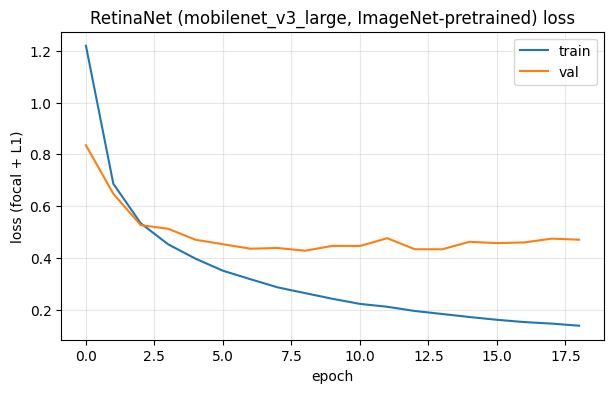

In [7]:
# 6. Loss curves (assignment: loss plots over epochs)
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="train"); plt.plot(history["val_loss"], label="val")
plt.xlabel("epoch"); plt.ylabel("loss (focal + L1)"); plt.title(f"RetinaNet ({MODEL_LABEL}) loss"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{WORK}/retinanet_pt_loss_curves.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
# 7. Test-set evaluation: mAP@50, mAP@50-95, precision / recall / F1 / mean IoU
from torchmetrics.detection import MeanAveragePrecision

model.load_state_dict(torch.load(CKPT_BEST, map_location=device))      # best (lowest val-loss) weights
model.eval(); model.score_thresh = 0.001; model.detections_per_img = 100

all_preds, all_tgts, times = [], [], []
with torch.no_grad():
    for imgs, tgts in tqdm(test_loader, desc="test"):
        imgs_d = [i.to(device) for i in imgs]
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        out = model(imgs_d)
        if device.type == "cuda": torch.cuda.synchronize()
        times.append((time.time() - t0) / len(imgs))
        for o, t in zip(out, tgts):
            all_preds.append({k: v.cpu() for k, v in o.items()})
            all_tgts.append({k: v.cpu() for k, v in t.items()})

mAP = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
mAP.update(all_preds, all_tgts)
r = mAP.compute()

def prf_at_conf(preds, tgts, conf=0.25, iou_thr=0.5, nc=NUM_CLASSES):
    tp, fp, fn, ious = np.zeros(nc), np.zeros(nc), np.zeros(nc), []
    for p, t in zip(preds, tgts):
        keep = p["scores"] >= conf
        pb, pl, ps = p["boxes"][keep], p["labels"][keep], p["scores"][keep]
        order = ps.argsort(descending=True); pb, pl = pb[order], pl[order]
        gb, gl = t["boxes"], t["labels"]
        matched = torch.zeros(len(gb), dtype=torch.bool)
        iou = box_iou(pb, gb) if len(pb) and len(gb) else None
        for i in range(len(pb)):
            c = int(pl[i]); hit = False
            if iou is not None:
                cand = (gl == c) & ~matched
                if cand.any():
                    row = iou[i].clone(); row[~cand] = -1
                    j = int(row.argmax())
                    if row[j] >= iou_thr:
                        matched[j] = True; hit = True; ious.append(float(row[j]))
            tp[c] += hit; fp[c] += (not hit)
        for c, m in zip(gl.tolist(), matched.tolist()):
            if not m: fn[c] += 1
    P = tp / np.maximum(tp + fp, 1); R = tp / np.maximum(tp + fn, 1); F1 = 2 * P * R / np.maximum(P + R, 1e-9)
    P_all = tp.sum() / max(tp.sum() + fp.sum(), 1); R_all = tp.sum() / max(tp.sum() + fn.sum(), 1)
    F_all = 2 * P_all * R_all / max(P_all + R_all, 1e-9)
    return P, R, F1, P_all, R_all, F_all, (np.mean(ious) if ious else 0.0)

P, R, F1, P_all, R_all, F_all, mean_iou = prf_at_conf(all_preds, all_tgts, conf=0.25)
ms_img = 1000 * float(np.mean(times))

per_class = pd.DataFrame({"class": CLASS_NAMES, "precision": P, "recall": R, "F1": F1})
if "map_per_class" in r and r["map_per_class"].numel() == NUM_CLASSES:
    per_class["mAP50-95"] = r["map_per_class"].numpy()
print(per_class.round(4).to_string(index=False))

summary = pd.DataFrame([{
    "Model": f"RetinaNet ({MODEL_LABEL})", "Params (M)": round(n_params / 1e6, 2), "GFLOPs": round(GFLOPS, 2),
    "Precision": round(P_all, 4), "Recall": round(R_all, 4), "F1": round(F_all, 4),
    "mAP@50": round(float(r["map_50"]), 4), "mAP@50-95": round(float(r["map"]), 4),
    "Mean IoU (TP)": round(mean_iou, 4), "ms/img": round(ms_img, 1), "FPS": round(1000 / ms_img, 1)}])
print("\n(precision / recall / F1 are at conf >= 0.25, IoU >= 0.5)")
print(summary.to_string(index=False))
summary.to_csv(f"{WORK}/retinanet_pt_results.csv", index=False); per_class.to_csv(f"{WORK}/retinanet_pt_per_class.csv", index=False)

test:   0%|          | 0/120 [00:00<?, ?it/s]

         class  precision  recall     F1  mAP50-95
         blade     0.2553  0.7059 0.3750    0.3415
      scissors     0.4565  0.7778 0.5753    0.5904
         knife     0.8421  1.0000 0.9143    0.7076
        dagger     0.7391  0.8947 0.8095    0.6459
SwissArmyKnife     0.3125  0.8824 0.4615    0.5423
 PlasticBottle     0.3874  0.8305 0.5283    0.4647
          Cans     0.1508  0.4043 0.2197    0.2401
     VacuumCup     0.5609  0.9470 0.7045    0.6695
   GlassBottle     0.0723  0.3945 0.1222    0.0418
  CartonDrinks     0.5606  0.7255 0.6325    0.5166
           Tin     0.2057  0.7347 0.3214    0.5299
     SprayCans     0.1366  0.2719 0.1818    0.0940

(precision / recall / F1 are at conf >= 0.25, IoU >= 0.5)
                                              Model  Params (M)  GFLOPs  Precision  Recall     F1  mAP@50  mAP@50-95  Mean IoU (TP)  ms/img  FPS
RetinaNet (mobilenet_v3_large, ImageNet-pretrained)       11.26  100.06     0.3282  0.7558 0.4577  0.6422     0.4487          0.839  

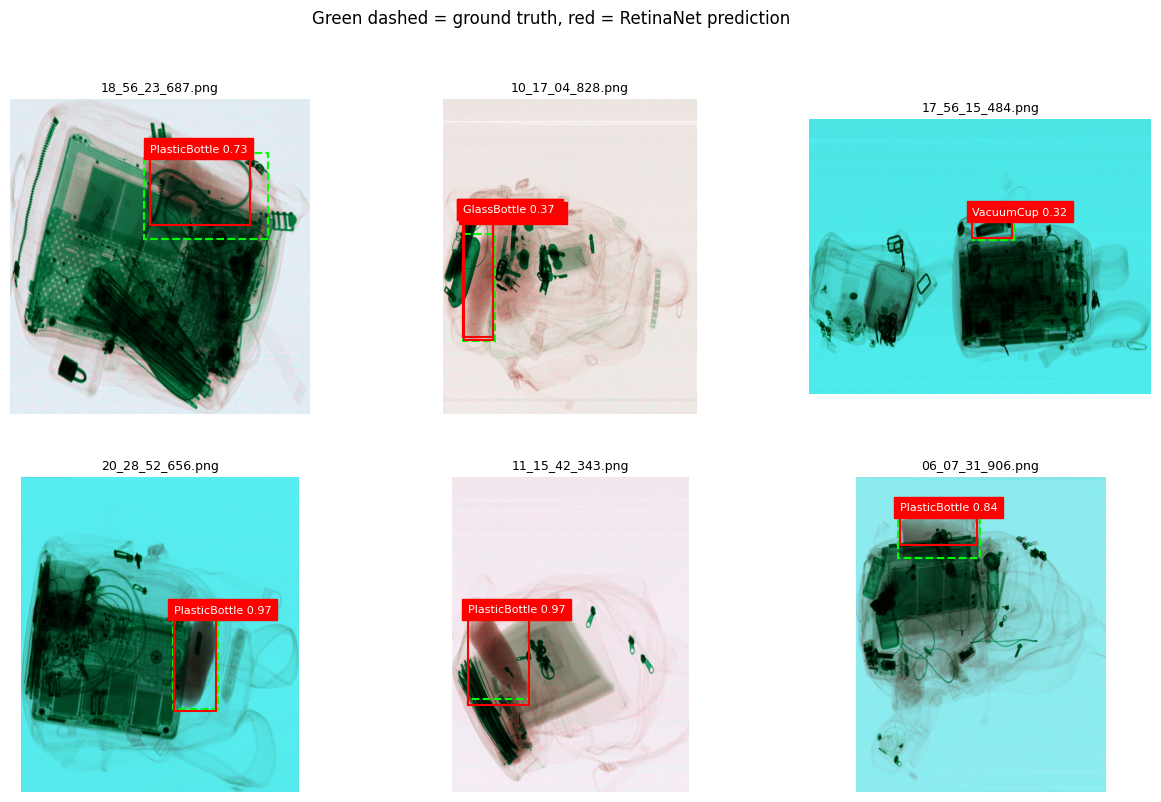

In [9]:
# 8. Sample prediction images (6 test images)
model.eval(); model.score_thresh = 0.3
idxs = random.Random(SEED).sample(range(len(test_ds)), 6)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, i in zip(axes.ravel(), idxs):
    img, tgt = test_ds[i]
    with torch.no_grad():
        out = model([img.to(device)])[0]
    ax.imshow(img.permute(1, 2, 0).numpy()); ax.axis("off")
    for b in tgt["boxes"]:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="lime", lw=1.5, ls="--"))
    for b, l, s in zip(out["boxes"].cpu(), out["labels"].cpu(), out["scores"].cpu()):
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
        ax.text(b[0], b[1], f"{CLASS_NAMES[int(l)]} {s:.2f}", color="white", fontsize=8, backgroundcolor="red")
    ax.set_title(os.path.basename(test_ds.files[i]), fontsize=9)
plt.suptitle("Green dashed = ground truth, red = RetinaNet prediction")
plt.savefig(f"{WORK}/retinanet_pt_samples.png", dpi=150, bbox_inches="tight"); plt.show()

## Extra evaluation graphs (confusion matrix, PR / F1 / P / R curves, per-class tables)
These cells only **re-use the test predictions** (`all_preds`, `all_tgts`) from section 7 - no retraining is needed.
Run section 7 first (if the session was restarted: re-run sections 1-4 and 7; the best weights are already saved in `retinanet_pt_best.pth`).
All figures are saved to `/kaggle/working/` with the prefix `retinanet_pt_`.

In [10]:
# 9. Post-hoc analysis: match detections to ground truth (class-aware, IoU >= thr, greedy by score)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
assert "all_preds" in globals() and "all_tgts" in globals(), "Run the test-set evaluation cell (section 7) first."

def to_np(x): return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)
PRED = [{"boxes": to_np(p["boxes"]).reshape(-1, 4), "scores": to_np(p["scores"]), "labels": to_np(p["labels"]).astype(int)} for p in all_preds]
GT   = [{"boxes": to_np(t["boxes"]).reshape(-1, 4), "labels": to_np(t["labels"]).astype(int)} for t in all_tgts]
NC = len(CLASS_NAMES)
N_GT  = np.bincount(np.concatenate([g["labels"] for g in GT]), minlength=NC)                 # instances per class
N_IMG = np.array([sum(c in g["labels"] for g in GT) for c in range(NC)])                     # images containing the class
print("test images:", len(GT), "| instances:", int(N_GT.sum()))

def iou_np(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)

def match_dataset(thr=0.5):
    """returns conf, predicted class, is-true-positive for every detection in the test set"""
    C, L, T = [], [], []
    for p, g in zip(PRED, GT):
        o = np.argsort(-p["scores"]); pb, ps, pl = p["boxes"][o], p["scores"][o], p["labels"][o]
        tp = np.zeros(len(pb), bool)
        if len(pb) and len(g["boxes"]):
            iou = iou_np(pb, g["boxes"]); used = np.zeros(len(g["boxes"]), bool)
            for i in range(len(pb)):
                cand = (g["labels"] == pl[i]) & ~used
                if cand.any():
                    row = np.where(cand, iou[i], -1.0); j = int(row.argmax())
                    if row[j] >= thr: used[j] = True; tp[i] = True
        C.append(ps); L.append(pl); T.append(tp)
    return np.concatenate(C), np.concatenate(L), np.concatenate(T)

def compute_ap(rec, prec):
    mrec = np.concatenate(([0.0], rec, [1.0])); mpre = np.concatenate(([1.0], prec, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    x = np.linspace(0, 1, 101); y = np.interp(x, mrec, mpre)
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2)), y

PX = np.linspace(0, 1, 1000)
def class_curves(conf, pcls, tp, c):
    m = pcls == c; ci, ti = conf[m], tp[m]
    if len(ci) == 0 or N_GT[c] == 0:
        return 0.0, np.zeros(101), np.zeros(1000), np.zeros(1000)
    o = np.argsort(-ci); ci, ti = ci[o], ti[o]
    tpc, fpc = np.cumsum(ti), np.cumsum(~ti)
    rec, prec = tpc / N_GT[c], tpc / np.maximum(tpc + fpc, 1)
    ap, prec101 = compute_ap(rec, prec)
    return ap, prec101, np.interp(-PX, -ci, prec, left=0), np.interp(-PX, -ci, rec, left=0)

# IoU = 0.50 matching (used for confusion matrix / curves / P-R-F1) and 0.50:0.95 AP (own implementation)
CONF, PCLS, TP50 = match_dataset(0.5)
AP_own = np.zeros((NC, 10))
for k, thr in enumerate(np.linspace(0.5, 0.95, 10)):
    cf, pc, tp_ = (CONF, PCLS, TP50) if k == 0 else match_dataset(thr)
    for c in range(NC): AP_own[c, k] = class_curves(cf, pc, tp_, c)[0]
AP50_own, AP5095_own = AP_own[:, 0], AP_own.mean(1)

# official per-class numbers from torchmetrics (same library as the headline mAP in section 7)
def _per_class(res):
    out = np.full(NC, np.nan)
    try:
        out[to_np(res["classes"]).astype(int)] = to_np(res["map_per_class"])
    except Exception: pass
    return out
try:
    from torchmetrics.detection import MeanAveragePrecision
    _m = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", iou_thresholds=[0.5], class_metrics=True)
    _m.update(all_preds, all_tgts); AP50_off = _per_class(_m.compute())
except Exception as e:
    print("torchmetrics AP50 unavailable, using own AP:", e); AP50_off = np.full(NC, np.nan)
AP5095_off = _per_class(r) if "r" in globals() else np.full(NC, np.nan)
AP50     = np.where(np.isnan(AP50_off), AP50_own, AP50_off)
AP5095   = np.where(np.isnan(AP5095_off), AP5095_own, AP5095_off)
print("AP source -> AP50:", "torchmetrics" if not np.isnan(AP50_off).any() else "own", "| AP50-95:", "torchmetrics" if not np.isnan(AP5095_off).any() else "own")
print(f"sanity check (own vs torchmetrics): mAP50 {AP50_own.mean():.4f} vs {(np.nanmean(AP50_off) if not np.isnan(AP50_off).all() else float("nan")):.4f} | mAP50-95 {AP5095_own.mean():.4f} vs {(np.nanmean(AP5095_off) if not np.isnan(AP5095_off).all() else float("nan")):.4f}")

test images: 956 | instances: 1421
AP source -> AP50: torchmetrics | AP50-95: torchmetrics
sanity check (own vs torchmetrics): mAP50 0.6433 vs 0.6422 | mAP50-95 0.4495 vs 0.4487


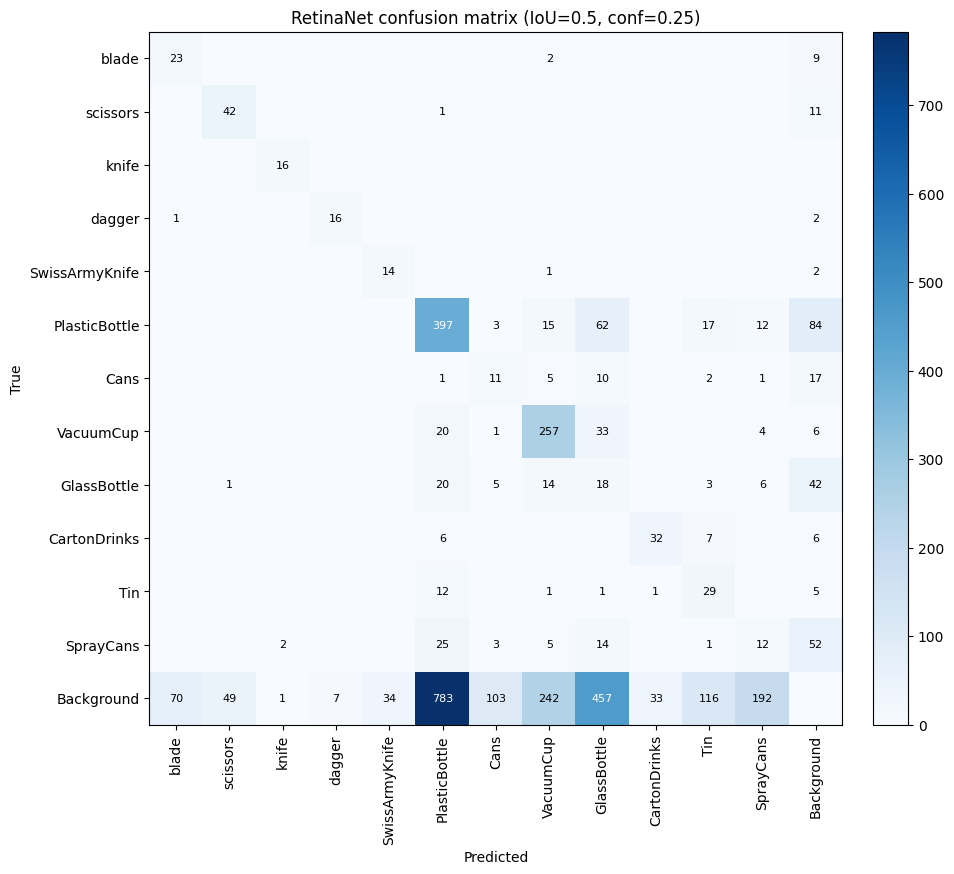

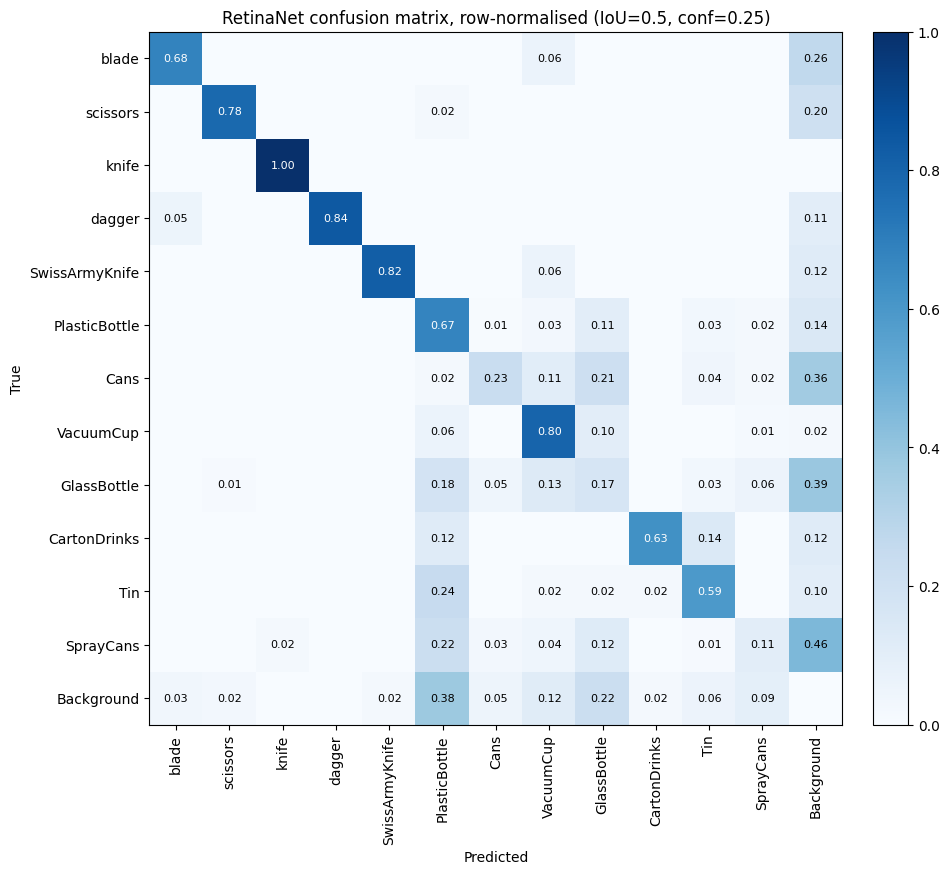

Rows = true class, columns = predicted class. Last column = missed objects (false negatives), last row = false positives.


In [11]:
# 10. Confusion matrix (IoU = 0.5, conf = 0.25) -- counts and row-normalised
def confusion(conf_thr=0.25, iou_thr=0.5):
    M = np.zeros((NC + 1, NC + 1), dtype=int)                  # [true, predicted], index NC = background
    for p, g in zip(PRED, GT):
        k = p["scores"] >= conf_thr; pb, pl = p["boxes"][k], p["labels"][k]; gb, gl = g["boxes"], g["labels"]
        if len(gb) == 0:
            for c in pl: M[NC, c] += 1
            continue
        if len(pb) == 0:
            for c in gl: M[c, NC] += 1
            continue
        iou = iou_np(gb, pb); gi, pi = np.nonzero(iou >= iou_thr); matched_g, matched_p = {}, set()
        if len(gi):
            m = np.stack([gi, pi, iou[gi, pi]], 1); m = m[m[:, 2].argsort()[::-1]]
            m = m[np.unique(m[:, 1], return_index=True)[1]]; m = m[m[:, 2].argsort()[::-1]]
            m = m[np.unique(m[:, 0], return_index=True)[1]]
            matched_g = {int(a): int(b) for a, b in m[:, :2]}; matched_p = set(matched_g.values())
        for j, c in enumerate(gl):
            M[c, pl[matched_g[j]] if j in matched_g else NC] += 1          # wrong class or missed (background)
        for i, c in enumerate(pl):
            if i not in matched_p: M[NC, c] += 1                         # false positive
    return M

def plot_cm(M, fname, title, norm=False):
    A = M.astype(float)
    if norm: A = A / np.maximum(A.sum(1, keepdims=True), 1)
    labels = list(CLASS_NAMES) + ["Background"]
    fig, ax = plt.subplots(figsize=(10, 9)); im = ax.imshow(A, cmap="Blues", vmin=0)
    ax.set_xticks(range(NC + 1)); ax.set_xticklabels(labels, rotation=90); ax.set_yticks(range(NC + 1)); ax.set_yticklabels(labels)
    for i in range(NC + 1):
        for j in range(NC + 1):
            v = A[i, j]
            if (norm and v >= 0.005) or (not norm and v > 0):
                ax.text(j, i, f"{v:.2f}" if norm else f"{int(v)}", ha="center", va="center", fontsize=8,
                        color="white" if v > A.max() * 0.5 else "black")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title); fig.colorbar(im, fraction=0.046, pad=0.04)
    fig.savefig(f"{WORK}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

CM = confusion(0.25, 0.5)
plot_cm(CM, "retinanet_pt_confusion_matrix.png", "RetinaNet confusion matrix (IoU=0.5, conf=0.25)")
plot_cm(CM, "retinanet_pt_confusion_matrix_normalized.png", "RetinaNet confusion matrix, row-normalised (IoU=0.5, conf=0.25)", norm=True)
pd.DataFrame(CM, index=[*CLASS_NAMES, "Background"], columns=[*CLASS_NAMES, "Background"]).to_csv(f"{WORK}/retinanet_pt_confusion_matrix.csv")
print("Rows = true class, columns = predicted class. Last column = missed objects (false negatives), last row = false positives.")

confidence with the best mean F1: 0.660  (P=0.808, R=0.588, F1=0.641)


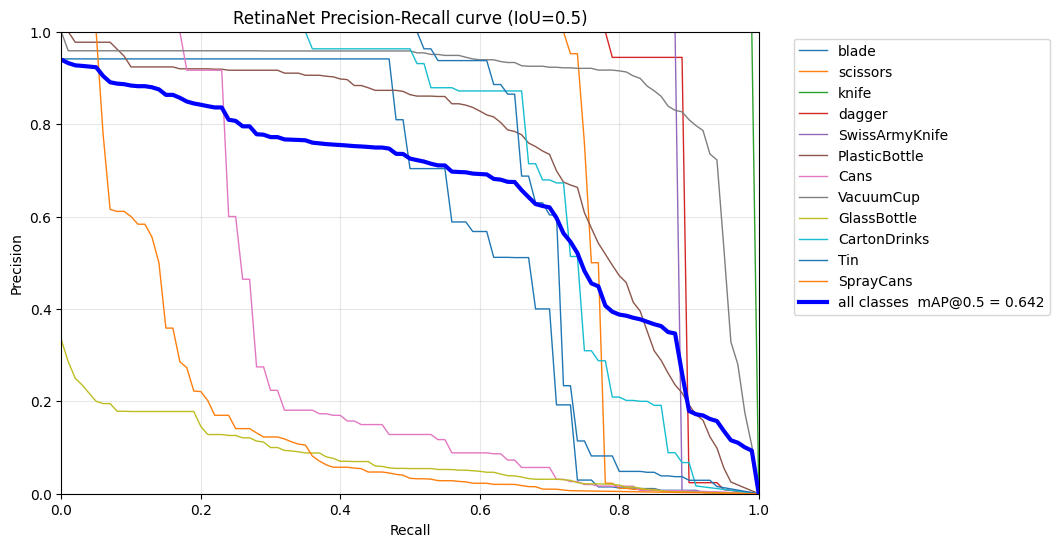

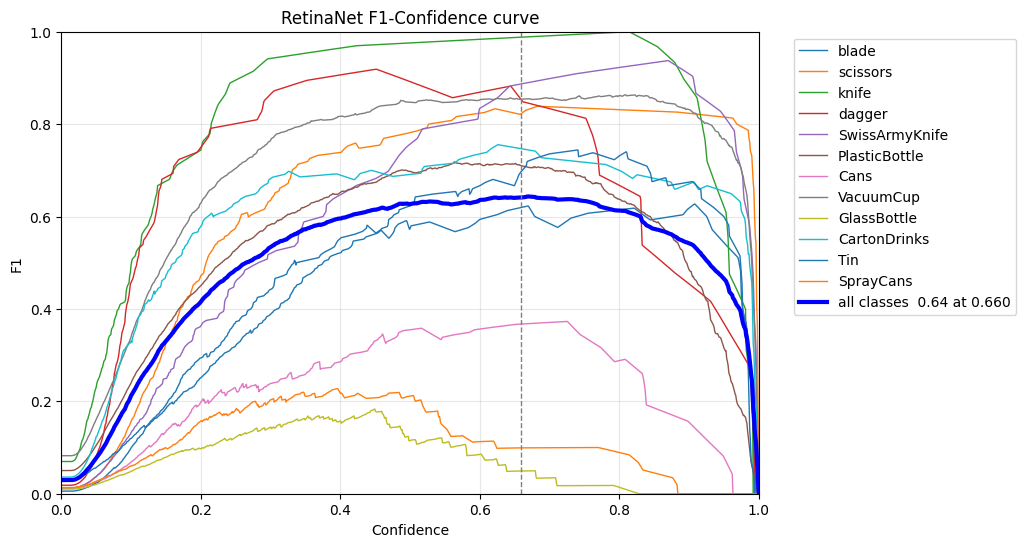

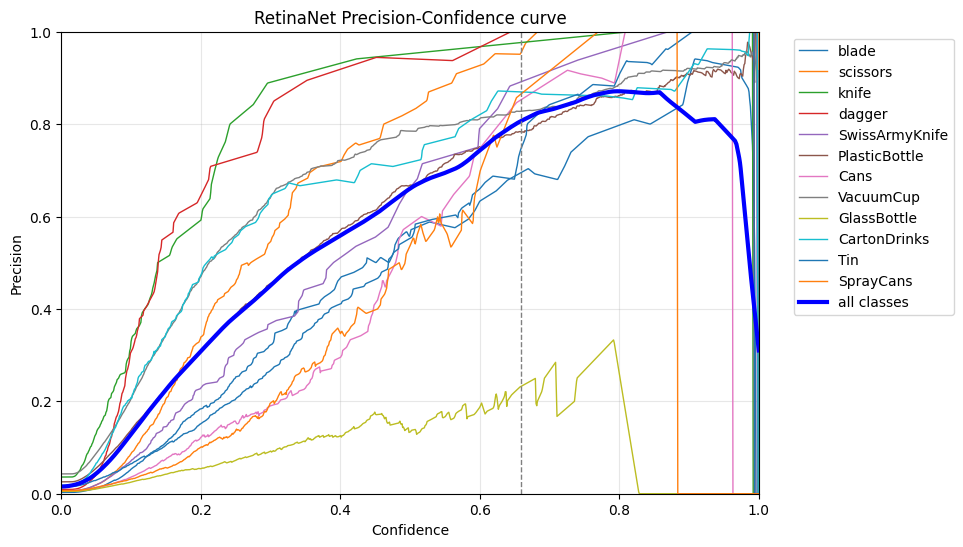

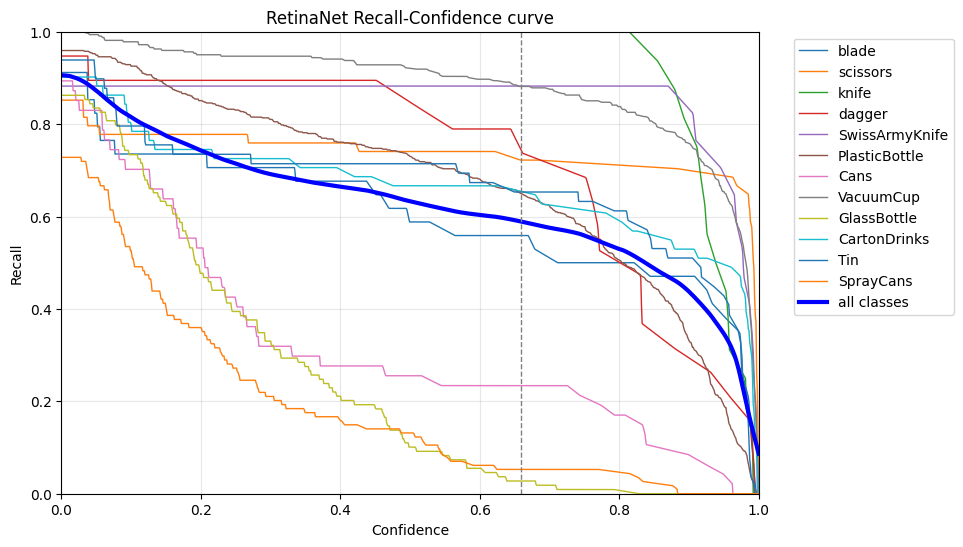

In [12]:
# 11. Precision-Recall, F1-confidence, Precision-confidence, Recall-confidence curves (IoU = 0.5)
def smooth(y, f=0.05):
    nf = round(len(y) * f * 2) // 2 + 1; p = np.ones(nf // 2)
    yp = np.concatenate((p * y[0], y, p * y[-1]), 0); return np.convolve(yp, np.ones(nf) / nf, mode="valid")

curves = [class_curves(CONF, PCLS, TP50, c) for c in range(NC)]
PREC101 = np.stack([c[1] for c in curves]); P_CURVE = np.stack([c[2] for c in curves]); R_CURVE = np.stack([c[3] for c in curves])
F1_CURVE = 2 * P_CURVE * R_CURVE / (P_CURVE + R_CURVE + 1e-16)
best_i = int(smooth(F1_CURVE.mean(0), 0.1).argmax()); BEST_CONF = float(PX[best_i])
print(f"confidence with the best mean F1: {BEST_CONF:.3f}  (P={P_CURVE[:, best_i].mean():.3f}, R={R_CURVE[:, best_i].mean():.3f}, F1={F1_CURVE[:, best_i].mean():.3f})")

def plot_curve(px, ys, xlabel, ylabel, fname, title, ylim=(0, 1), mean_label=None, mark_x=None):
    fig, ax = plt.subplots(figsize=(9, 6))
    for i, y in enumerate(ys): ax.plot(px, y, linewidth=1, label=CLASS_NAMES[i])
    ym = smooth(ys.mean(0), 0.05) if mean_label is None else ys.mean(0)
    ax.plot(px, ym, linewidth=3, color="blue", label=mean_label or "all classes")
    if mark_x is not None: ax.axvline(mark_x, color="gray", ls="--", lw=1)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_xlim(0, 1); ax.set_ylim(*ylim); ax.set_title(title); ax.grid(alpha=.3)
    ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left"); fig.savefig(f"{WORK}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

x101 = np.linspace(0, 1, 101)
plot_curve(x101, PREC101, "Recall", "Precision", "retinanet_pt_PR_curve.png", "RetinaNet Precision-Recall curve (IoU=0.5)",
           mean_label=f"all classes  mAP@0.5 = {AP50.mean():.3f}")
plot_curve(PX, F1_CURVE, "Confidence", "F1", "retinanet_pt_F1_curve.png", "RetinaNet F1-Confidence curve",
           mean_label=f"all classes  {F1_CURVE[:, best_i].mean():.2f} at {BEST_CONF:.3f}", mark_x=BEST_CONF)
plot_curve(PX, P_CURVE, "Confidence", "Precision", "retinanet_pt_P_curve.png", "RetinaNet Precision-Confidence curve", mark_x=BEST_CONF)
plot_curve(PX, R_CURVE, "Confidence", "Recall", "retinanet_pt_R_curve.png", "RetinaNet Recall-Confidence curve", mark_x=BEST_CONF)

=== per-class test results, conf >= 0.25, IoU >= 0.5 (macro = mean over classes) ===
         class  images  instances  precision  recall     F1  mAP50  mAP50-95
         blade      27         34     0.2553  0.7059 0.3750 0.5909    0.3415
      scissors      51         54     0.4565  0.7778 0.5753 0.7601    0.5904
         knife      16         16     0.8421  1.0000 0.9143 1.0000    0.7076
        dagger      19         19     0.7391  0.8947 0.8095 0.8862    0.6459
SwissArmyKnife      17         17     0.3125  0.8824 0.4615 0.8812    0.5423
 PlasticBottle     488        590     0.3874  0.8305 0.5283 0.7213    0.4647
          Cans      37         47     0.1508  0.4043 0.2197 0.3138    0.2401
     VacuumCup     314        321     0.5609  0.9470 0.7045 0.8917    0.6695
   GlassBottle      83        109     0.0723  0.3945 0.1222 0.0801    0.0418
  CartonDrinks      46         51     0.5606  0.7255 0.6325 0.7209    0.5166
           Tin      45         49     0.2057  0.7347 0.3214 0.6965  

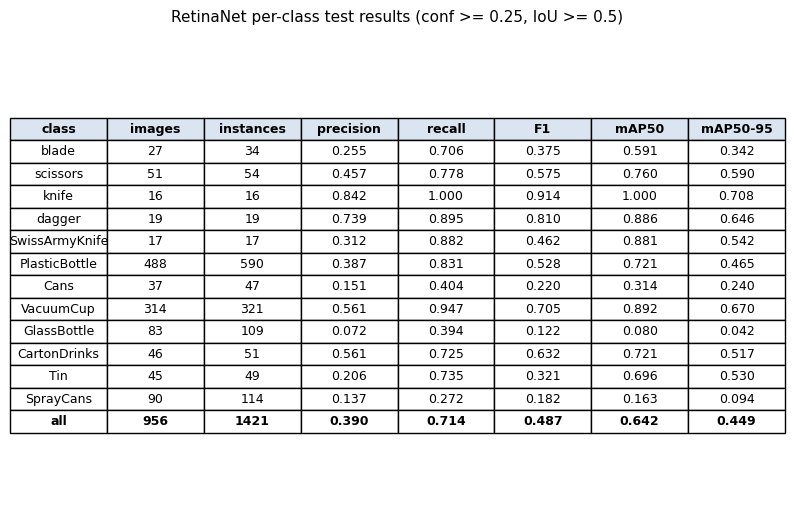

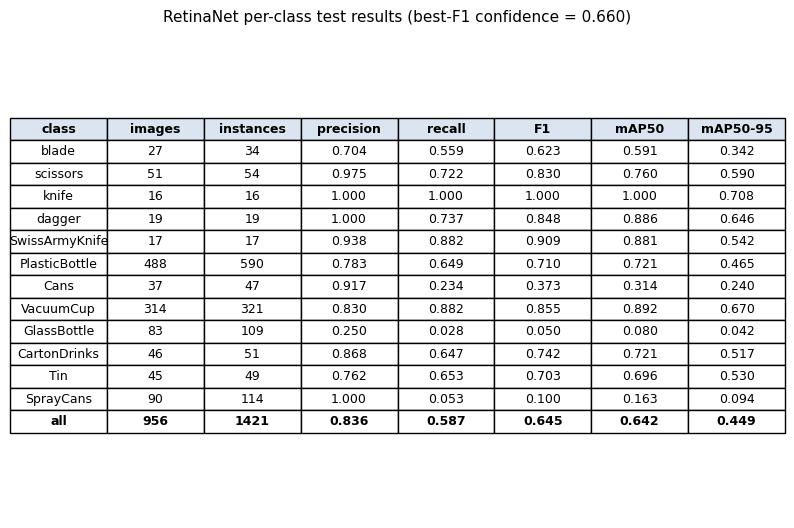

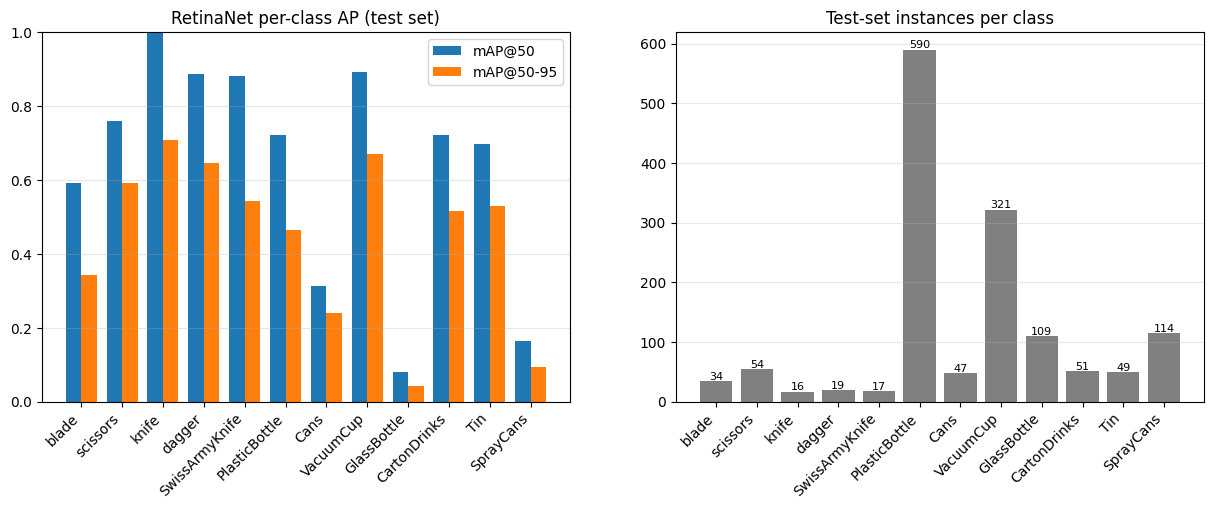

In [13]:
# 12. Per-class results tables (same columns as the other models) + per-class bar chart
def prf_at(conf_thr):
    keep = CONF >= conf_thr
    tpc = np.bincount(PCLS[keep & TP50], minlength=NC); npred = np.bincount(PCLS[keep], minlength=NC)
    P = tpc / np.maximum(npred, 1); R = tpc / np.maximum(N_GT, 1); F1 = 2 * P * R / np.maximum(P + R, 1e-9)
    Pm = tpc.sum() / max(npred.sum(), 1); Rm = tpc.sum() / max(N_GT.sum(), 1)
    return P, R, F1, (Pm, Rm, 2 * Pm * Rm / max(Pm + Rm, 1e-9))     # per-class arrays, micro (P, R, F1)

def class_table(conf_thr):
    P, R, F1, micro = prf_at(conf_thr)
    df = pd.DataFrame({"class": CLASS_NAMES, "images": N_IMG, "instances": N_GT, "precision": P, "recall": R, "F1": F1,
                       "mAP50": AP50, "mAP50-95": AP5095})
    allrow = {"class": "all", "images": len(GT), "instances": int(N_GT.sum()), "precision": P.mean(), "recall": R.mean(),
              "F1": F1.mean(), "mAP50": AP50.mean(), "mAP50-95": AP5095.mean()}
    return pd.concat([df, pd.DataFrame([allrow])], ignore_index=True), micro

def table_png(df, title, fname):
    d = df.copy()
    for c in d.columns[3:]: d[c] = d[c].map(lambda v: f"{v:.3f}")
    fig, ax = plt.subplots(figsize=(10, 0.42 * (len(d) + 2))); ax.axis("off")
    t = ax.table(cellText=d.values, colLabels=d.columns, loc="center", cellLoc="center"); t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1, 1.35)
    for j in range(len(d.columns)): t[0, j].set_facecolor("#dbe5f1"); t[0, j].set_text_props(weight="bold")
    for j in range(len(d.columns)): t[len(d), j].set_text_props(weight="bold")
    ax.set_title(title, fontsize=11, pad=8); fig.savefig(f"{WORK}/{fname}", dpi=170, bbox_inches="tight"); plt.show()

tab25, micro25 = class_table(0.25)
tabbest, microbest = class_table(BEST_CONF)
print("=== per-class test results, conf >= 0.25, IoU >= 0.5 (macro = mean over classes) ===");  print(tab25.round(4).to_string(index=False))
print(f"micro  P={micro25[0]:.4f}  R={micro25[1]:.4f}  F1={micro25[2]:.4f}")
print(f"\n=== per-class test results at the best-F1 confidence ({BEST_CONF:.3f}) -- the way Ultralytics reports P / R ===");  print(tabbest.round(4).to_string(index=False))
print(f"micro  P={microbest[0]:.4f}  R={microbest[1]:.4f}  F1={microbest[2]:.4f}")
tab25.to_csv(f"{WORK}/retinanet_pt_per_class_conf025.csv", index=False); tabbest.to_csv(f"{WORK}/retinanet_pt_per_class_bestF1.csv", index=False)
table_png(tab25, "RetinaNet per-class test results (conf >= 0.25, IoU >= 0.5)", "retinanet_pt_per_class_table_conf025.png")
table_png(tabbest, f"RetinaNet per-class test results (best-F1 confidence = {BEST_CONF:.3f})", "retinanet_pt_per_class_table_bestF1.png")

# per-class bar chart + class distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8)); xs = np.arange(NC); w = 0.38
axes[0].bar(xs - w / 2, AP50, w, label="mAP@50"); axes[0].bar(xs + w / 2, AP5095, w, label="mAP@50-95")
axes[0].set_xticks(xs); axes[0].set_xticklabels(CLASS_NAMES, rotation=45, ha="right"); axes[0].set_ylim(0, 1); axes[0].legend(); axes[0].grid(alpha=.3, axis="y")
axes[0].set_title("RetinaNet per-class AP (test set)")
axes[1].bar(xs, N_GT, color="gray"); axes[1].set_xticks(xs); axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[1].set_title("Test-set instances per class"); axes[1].grid(alpha=.3, axis="y")
for i, v in enumerate(N_GT): axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
fig.savefig(f"{WORK}/retinanet_pt_per_class_bars.png", dpi=150, bbox_inches="tight"); plt.show()

                                                                           0
Model                    RetinaNet (mobilenet_v3_large, ImageNet-pretrained)
Params (M)                                                             11.26
GFLOPs                                                                100.06
Precision (macro)                                                       0.39
Recall (macro)                                                        0.7141
F1 (macro)                                                            0.4872
mAP@50                                                                0.6422
mAP@50-95                                                             0.4487
Mean IoU (TP)                                                          0.839
ms/img                                                                  34.4
FPS                                                                     29.1
Epochs run                                                                19

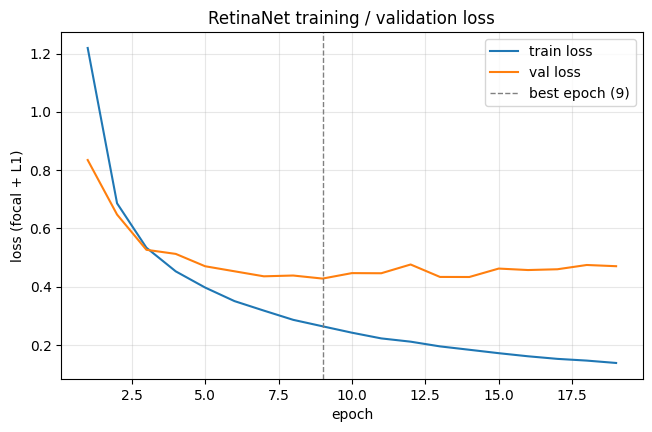

saved -> /kaggle/working/retinanet_graphs.zip (download this from the Output tab)


In [14]:
# 13. Final summary table (same rows as the other models), training curves with best epoch, and zip of all figures
epochs_run = len(history["train_loss"]); best_epoch = int(np.argmin(history["val_loss"])) + 1
_g = lambda n, d=float("nan"): globals().get(n, d)
final = pd.Series({
    "Model": f"RetinaNet ({MODEL_LABEL})", "Params (M)": round(n_params / 1e6, 2), "GFLOPs": round(_g("GFLOPS"), 2),
    "Precision (macro)": round(tab25.iloc[-1]["precision"], 4), "Recall (macro)": round(tab25.iloc[-1]["recall"], 4), "F1 (macro)": round(tab25.iloc[-1]["F1"], 4),
    "mAP@50": round(float(r["map_50"]) if "r" in globals() else AP50.mean(), 4), "mAP@50-95": round(float(r["map"]) if "r" in globals() else AP5095.mean(), 4),
    "Mean IoU (TP)": round(_g("mean_iou"), 4), "ms/img": round(_g("ms_img"), 1), "FPS": round(1000 / _g("ms_img"), 1),
    "Epochs run": epochs_run, "Best epoch": best_epoch,
    "Precision @best-F1 conf": round(tabbest.iloc[-1]["precision"], 4), "Recall @best-F1 conf": round(tabbest.iloc[-1]["recall"], 4),
    "F1 @best-F1 conf": round(tabbest.iloc[-1]["F1"], 4), "best-F1 conf": round(BEST_CONF, 3)}, name=0)
print(final.to_frame().to_string())
print(f"\nPrecision/recall/F1: conf >= 0.25, IoU >= 0.5, class-averaged (micro: P={micro25[0]:.4f} R={micro25[1]:.4f} F1={micro25[2]:.4f})")
final.to_frame().T.to_csv(f"{WORK}/retinanet_pt_final_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.5)); ep = np.arange(1, epochs_run + 1)
ax.plot(ep, history["train_loss"], label="train loss"); ax.plot(ep, history["val_loss"], label="val loss")
ax.axvline(best_epoch, color="gray", ls="--", lw=1, label=f"best epoch ({best_epoch})")
ax.set_xlabel("epoch"); ax.set_ylabel("loss (focal + L1)"); ax.set_title("RetinaNet training / validation loss"); ax.legend(); ax.grid(alpha=.3)
fig.savefig(f"{WORK}/retinanet_pt_loss_curves_best_epoch.png", dpi=150, bbox_inches="tight"); plt.show()

import glob, zipfile
with zipfile.ZipFile(f"{WORK}/retinanet_graphs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(glob.glob(f"{WORK}/retinanet_pt_*.png") + glob.glob(f"{WORK}/retinanet_pt_*.csv")): z.write(f, os.path.basename(f))
print("saved ->", f"{WORK}/retinanet_graphs.zip", "(download this from the Output tab)")